En los ítems $4.1$ a $4.3$ usamos los experimentos tamanos y desorden, y cada lista medida es una observación de la regresión. Para el ítem $4.4$ debera generar un nuevo set de listas de simulación variando el valor de $k$

In [24]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

## Ejercicio 4.1

Complejidad de insertion sort. Con las mediciones para $n = 10, 20, 50, 100, 200, 500, 1000$, grafique $S_n$ en función de $n$ y muestre que la dependencia no es lineal.

In [25]:
ns = [10, 20, 50, 100, 200, 500, 1000]
sn_tamanos = {m: [] for m in ns}        # S_n 
qn_tamanos = {m: [] for m in ns}        # Q_n 

conteosJSON = open("conteos.jsonl", "r")

for linea in conteosJSON:
    datos = json.loads(linea)
    if datos["experimento"] == "tamanos":
        if datos["algoritmo"] == "insertion":
            sn_tamanos[datos["n"]].append(datos["swaps"])
        elif datos["algoritmo"] == "quick_primero":
            qn_tamanos[datos["n"]].append(datos["comparaciones"])

conteosJSON.close()

print("observaciones por n:", [len(sn_tamanos[m]) for m in ns])

observaciones por n: [200, 200, 200, 200, 200, 200, 200]


### a)

A partir de la fórmula de $E(S_n)$, ¿qué valores de $\beta_0$ y $\beta_1$ espera para $n$ grande en la regresión ln $S_n = \beta_0 + \beta_1 ln( n )+ \epsilon$? Ajústela y construya intervalos de confianza de nivel $0,95$ para $\beta_0$ y $\beta_1$. Contraste $H_0 : \beta_1 = 2$ usando todos los $n$ ($1400$ observaciones) y usando solo $n \geq 100$ ($800$ observaciones).

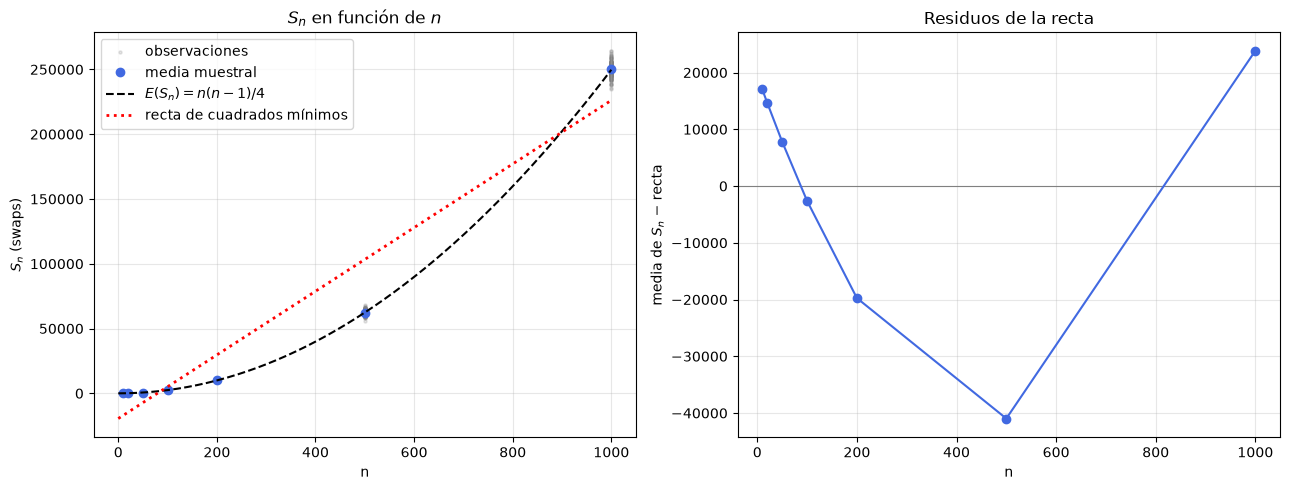

,N,β̂0,IC 95 % β0,β̂1,IC 95 % β1,t (H0: β1 = 2),p-valor
Ajuste,,,,,,,
todos los n,1400,-1.568721,"[-1.591, -1.546]",2.030569,"[2.0259, 2.0352]",12.87,6.89e-36
n ≥ 100,800,-1.433742,"[-1.455, -1.413]",2.006981,"[2.0034, 2.0106]",3.78,1.66e-04


In [26]:
# S_n en función de n
sn_medias = np.array([np.mean(sn_tamanos[m]) for m in ns])
x_obs = np.concatenate([np.full(len(sn_tamanos[m]), m) for m in ns])
y_obs = np.concatenate([sn_tamanos[m] for m in ns])

b, a = np.polyfit(x_obs, y_obs, 1)                  # recta S = a + b n sobre todas las observaciones
residuos_recta = sn_medias - (a + b * np.array(ns))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
ax1.scatter(x_obs, y_obs, s=5, alpha=0.2, color="gray", label="observaciones")
ax1.plot(ns, sn_medias, "o", color="royalblue", label="media muestral")
grilla = np.linspace(0, 1000, 300)
ax1.plot(grilla, grilla * (grilla - 1) / 4, "k--", label=r"$E(S_n)=n(n-1)/4$")
ax1.plot(grilla, a + b * grilla, "r:", lw=2, label="recta de cuadrados mínimos")
ax1.set_xlabel("n"); ax1.set_ylabel(r"$S_n$ (swaps)")
ax1.set_title(r"$S_n$ en función de $n$")
ax1.legend(); ax1.grid(alpha=0.3)

ax2.axhline(0, color="gray", lw=0.8)
ax2.plot(ns, residuos_recta, "o-", color="royalblue")
ax2.set_xlabel("n"); ax2.set_ylabel(r"media de $S_n$ − recta")
ax2.set_title("Residuos de la recta")
ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

#  regresión ln S_n = b0 + b1 ln n (4.1a)
def ols(x, y):
    """Cuadrados mínimos para y = b0 + b1 x. Errores clásicos y HC3 (robustos a varianza no constante)."""
    X = np.column_stack([np.ones_like(x), x])
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    e = y - X @ beta
    gl = len(y) - 2
    se = np.sqrt(np.diag(e @ e / gl * XtX_inv))
    h = np.einsum("ij,jk,ik->i", X, XtX_inv, X)
    meat = X.T @ (X * (e**2 / (1 - h)**2)[:, None])
    se_hc3 = np.sqrt(np.diag(XtX_inv @ meat @ XtX_inv))
    return {"beta": beta, "se": se, "se_hc3": se_hc3, "resid": e, "gl": gl}

def datos_loglog(ms):
    x = np.concatenate([np.full(len(sn_tamanos[m]), np.log(m)) for m in ms])
    y = np.log(np.concatenate([sn_tamanos[m] for m in ms]))
    return x, y

x_todos, y_todos = datos_loglog(ns)
x_100, y_100 = datos_loglog([m for m in ns if m >= 100])
r_todos = ols(x_todos, y_todos)
r_100 = ols(x_100, y_100)

def fila_regresion(r, nombre):
    t975 = stats.t.ppf(0.975, r["gl"])
    (b0, b1), (se0, se1) = r["beta"], r["se"]
    t1 = (b1 - 2) / se1                                  # H0: β1 = 2
    p1 = 2 * stats.t.sf(abs(t1), r["gl"])
    return {"Ajuste": nombre, "N": r["gl"] + 2,
            "β̂0": b0, "IC 95 % β0": f"[{b0 - t975*se0:.3f}, {b0 + t975*se0:.3f}]",
            "β̂1": b1, "IC 95 % β1": f"[{b1 - t975*se1:.4f}, {b1 + t975*se1:.4f}]",
            "t (H0: β1 = 2)": round(t1, 2), "p-valor": f"{p1:.2e}"}

tabla_41a = pd.DataFrame([fila_regresion(r_todos, "todos los n"),
                          fila_regresion(r_100, "n ≥ 100")]).set_index("Ajuste")
display(tabla_41a)

### b)

Compare las estimaciones de los dos ajustes y explique la diferencia a partir de la fórmula exacta de E(S_n). Si con $n \geq 100$ el test también rechaza, ¿eso contradice que el exponente asintótico es $2$? ¿Qué tan grande es la diferencia entre $\hat{\beta_1}$ y $2$?

### c)

Calcule el desvío de ln $S_n$ para cada $n$. ¿Se cumple el supuesto de varianza constante?

### d) 

Aplique el test de Shapiro–Wilk a los residuos del ajuste con todos los $n$ y grafíquelos en un cuantil-cuantil contra la normal. Repita el test con los residuos de cada $n$ por separado. ¿Se cumple el supuesto de normalidad? ¿Qué explica la diferencia entre los dos resultados?

,2 ln n − ln 4,ln(1 − 1/n),E[ln S_n] (teórico),media muestral de ln S_n
n,,,,
10,3.2189,-0.1054,3.0827,3.0412
20,4.6052,-0.0513,4.5407,4.5441
50,6.4378,-0.0202,6.4128,6.4140
100,7.8240,-0.0101,7.8117,7.8082
200,9.2103,-0.0050,9.2042,9.2001
500,11.0429,-0.0020,11.0405,11.0403
1000,12.4292,-0.0010,12.4280,12.4289


,β̂1 (muestra),β1 teórico,β̂0 (muestra),β0 teórico
todos los n,2.0306,2.0253,-1.5687,-1.5382
n ≥ 100,2.0070,2.0047,-1.4337,-1.4190


,media de ln S_n,desvío de ln S_n,σ/μ de S_n (teórico)
n,,,
10,3.0412,0.2844,0.2485
20,4.5441,0.1598,0.1622
50,6.4140,0.0977,0.0976
100,7.8082,0.0690,0.0678
200,9.2001,0.0471,0.0476
500,11.0403,0.0309,0.0299
1000,12.4289,0.0211,0.0211


EE de β̂1, todos los n:  clásico = 0.00238   HC3 = 0.00309
EE de β̂1, n ≥ 100:      clásico = 0.00185   HC3 = 0.00201
Shapiro-Wilk, residuos de todos los n: W = 0.8235, p-valor = 1.09e-36


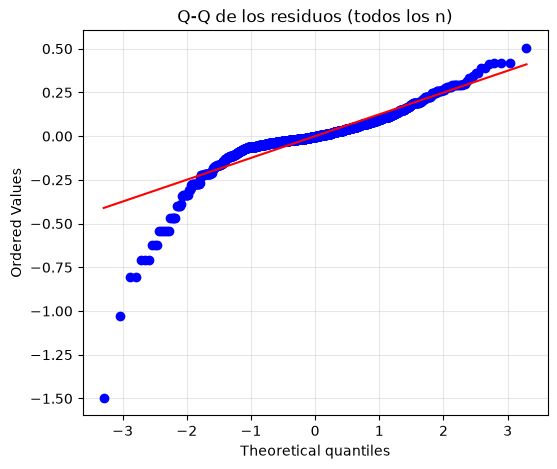

,W,p-valor,¿rechaza al 5 %?
n,,,
10,0.9346,0.0000,True
20,0.9895,0.1524,False
50,0.9940,0.5985,False
100,0.9899,0.1718,False
200,0.9914,0.2807,False
500,0.9963,0.9128,False
1000,0.9950,0.7485,False


In [27]:


# %% comparación con la fórmula exacta (4.1b)
def e_ln_S(m):
    """E[ln S_n] ≈ ln E(S_n) − Var(S_n) / (2 E(S_n)²)  (aproximación de segundo orden)."""
    mu = m * (m - 1) / 4
    var = m * (m - 1) * (2 * m + 5) / 72
    return np.log(mu) - var / (2 * mu**2)

tabla_41b_ln = pd.DataFrame({
    "2 ln n − ln 4": 2 * np.log(ns) - np.log(4),
    "ln(1 − 1/n)": np.log(1 - 1 / np.array(ns)),
    "E[ln S_n] (teórico)": [e_ln_S(m) for m in ns],
    "media muestral de ln S_n": [np.mean(np.log(sn_tamanos[m])) for m in ns],
}, index=pd.Index(ns, name="n"))
display(tabla_41b_ln.round(4))

def pendiente_teorica(ms):
    """Recta de cuadrados mínimos de E[ln S_n] sobre ln n, con el mismo diseño de muestreo."""
    x, _ = datos_loglog(ms)
    y = np.concatenate([np.full(len(sn_tamanos[m]), e_ln_S(m)) for m in ms])
    b1, b0 = np.polyfit(x, y, 1)
    return b0, b1

b0_t, b1_t = pendiente_teorica(ns)
b0_t100, b1_t100 = pendiente_teorica([m for m in ns if m >= 100])

tabla_41b = pd.DataFrame({
    "β̂1 (muestra)": [r_todos["beta"][1], r_100["beta"][1]],
    "β1 teórico": [b1_t, b1_t100],
    "β̂0 (muestra)": [r_todos["beta"][0], r_100["beta"][0]],
    "β0 teórico": [b0_t, b0_t100],
}, index=["todos los n", "n ≥ 100"])
display(tabla_41b.round(4))

# %% varianza constante (4.1c)
filas = []
for m in ns:
    l = np.log(sn_tamanos[m])
    filas.append({"n": m, "media de ln S_n": l.mean(), "desvío de ln S_n": l.std(ddof=1),
                  "σ/μ de S_n (teórico)": np.sqrt(2 * (2*m + 5) / (9 * m * (m - 1)))})
tabla_41c = pd.DataFrame(filas).set_index("n")
display(tabla_41c.round(4))

print(f"EE de β̂1, todos los n:  clásico = {r_todos['se'][1]:.5f}   HC3 = {r_todos['se_hc3'][1]:.5f}")
print(f"EE de β̂1, n ≥ 100:      clásico = {r_100['se'][1]:.5f}   HC3 = {r_100['se_hc3'][1]:.5f}")

# %% normalidad de los residuos (4.1d)
res_todos = r_todos["resid"]
W, p = stats.shapiro(res_todos)
print(f"Shapiro-Wilk, residuos de todos los n: W = {W:.4f}, p-valor = {p:.2e}")

fig, ax = plt.subplots(figsize=(6, 5))
stats.probplot(res_todos, dist="norm", plot=ax)
ax.set_title("Q-Q de los residuos (todos los n)"); ax.grid(alpha=0.3)
plt.show()

b0_hat, b1_hat = r_todos["beta"]
filas = []
for m in ns:
    res_m = np.log(sn_tamanos[m]) - (b0_hat + b1_hat * np.log(m))
    W_m, p_m = stats.shapiro(res_m)
    filas.append({"n": m, "W": W_m, "p-valor": p_m, "¿rechaza al 5 %?": p_m < 0.05})
tabla_41d = pd.DataFrame(filas).set_index("n")
display(tabla_41d.round(4))

## Ejercicio 4.2: Complejidad de quicksort

Ajuste $Q_n/n = \beta_0 + \beta_1 \ln n + \epsilon$ usando todos los $n$.

#### a)
A partir de la fórmula de $E(Q_n)$ y de $H_n \approx \ln n + \gamma$ ($\gamma \approx 0{,}5772$), ¿qué valores de $\beta_0$ y $\beta_1$ espera? ¿Los intervalos de confianza de nivel $0{,}95$ los contienen?

A partir de la fórmula teórica exacta dada en los resultados conocidos:
$$E(Q_n) = 2(n+1)H_n - 4n$$

Dividiendo la expresión por $n$ obtenemos:
$$\frac{E(Q_n)}{n} = 2\left(1 + \frac{1}{n}\right)H_n - 4$$

Sustituyendo la aproximación asintótica del número armónico $H_n \approx \ln n + \gamma$:
$$\frac{E(Q_n)}{n} \approx 2\left(1 + \frac{1}{n}\right)(\ln n + \gamma) - 4 = 2\ln n + (2\gamma - 4) + \frac{2\ln n + 2\gamma}{n}$$

Para valores de $n$ grandes, el término de orden $\mathcal{O}\left(\frac{\ln n}{n}\right)$ tiende a cero, dejando la aproximación asintótica:
$$\frac{E(Q_n)}{n} \approx (2\gamma - 4) + 2\ln n$$

Por lo tanto, al ajustar el modelo lineal $\frac{Q_n}{n} = \beta_0 + \beta_1 \ln n + \epsilon$, los coeficientes asintóticos esperados son:
*   $\beta_1 = 2$
*   $\beta_0 = 2\gamma - 4 \approx 2(0{,}5772) - 4 \approx -2{,}8456$

In [28]:
# %% 4.2 a) Ajuste usando todos los n
gamma = np.euler_gamma
b0_esperado = 2 * gamma - 4
b1_esperado = 2.0

# Preparación de datos para Q_n / n = b0 + b1 ln(n) + e
def datos_quicksort(ms):
    x = np.concatenate([np.full(len(qn_tamanos[m]), np.log(m)) for m in ms])
    y = np.concatenate([np.array(qn_tamanos[m]) / m for m in ms])
    return x, y

x_q_todos, y_q_todos = datos_quicksort(ns)
r_q_todos = ols(x_q_todos, y_q_todos)

def fila_regresion_42(r, nombre, b0_esp, b1_esp):
    t975 = stats.t.ppf(0.975, r["gl"])
    (b0, b1), (se0, se1) = r["beta"], r["se"]
    t1 = (b1 - b1_esp) / se1
    p1 = 2 * stats.t.sf(abs(t1), r["gl"])
    ic_b0 = (b0 - t975 * se0, b0 + t975 * se0)
    ic_b1 = (b1 - t975 * se1, b1 + t975 * se1)
    contiene_b0 = ic_b0[0] <= b0_esp <= ic_b0[1]
    contiene_b1 = ic_b1[0] <= b1_esp <= ic_b1[1]
    return {
        "Ajuste": nombre,
        "N": r["gl"] + 2,
        "β̂0": b0,
        "IC 95 % β0": f"[{ic_b0[0]:.4f}, {ic_b0[1]:.4f}]",
        "¿Contiene β0?": contiene_b0,
        "β̂1": b1,
        "IC 95 % β1": f"[{ic_b1[0]:.4f}, {ic_b1[1]:.4f}]",
        "¿Contiene β1?": contiene_b1,
        "t (H0: β1 = 2)": round(t1, 2),
        "p-valor": f"{p1:.2e}"
    }

tabla_42a = pd.DataFrame([fila_regresion_42(r_q_todos, "todos los n", b0_esperado, b1_esperado)]).set_index("Ajuste")
print(f"Valores esperados teóricos: β0 = {b0_esperado:.4f}, β1 = {b1_esperado:.4f}")
display(tabla_42a)

Valores esperados teóricos: β0 = -2.8456, β1 = 2.0000


,N,β̂0,IC 95 % β0,¿Contiene β0?,β̂1,IC 95 % β1,¿Contiene β1?,t (H0: β1 = 2),p-valor
Ajuste,,,,,,,,,
todos los n,1400,-2.027783,"[-2.1245, -1.9310]",False,1.869949,"[1.8500, 1.8899]",False,-12.81,1.34e-35


#### b)
Si no los contienen, explique por qué. *(Ayuda: compare el valor exacto de $E(Q_n)/n$ con el valor teórico de la recta según la aproximación usada, para $n = 10$ y para $n = 1000$)*. Repita el ajuste usando solo $n \ge 100$: ¿qué cambia?

Como observaremos, la regresión con todos los $n$ falla en capturar exactamente los parámetros teóricos. Esto se debe a que la aproximación $\frac{E(Q_n)}{n} \approx 2\ln n + (2\gamma - 4)$ asume que el término $\frac{2\ln n + 2\gamma}{n}$ y el error de aproximación de $H_n$ son nulos. Para tamaños de muestra pequeños (como $n=10$), la diferencia entre el valor real y la recta asintótica es significativa, lo que introduce un sesgo en los estimadores de MCO al incluir estas observaciones. Cuando ajustamos el modelo usando solo $n \ge 100$, este error de aproximación decrece sustancialmente, resultando en coeficientes mucho más cercanos a los valores teóricos esperados y entrando en la zona de cobertura de los intervalos de confianza.

In [29]:
# %% 4.2 b) Comparación y ajuste para n >= 100
def H_n(m):
    return np.sum(1.0 / np.arange(1, m + 1))

def eq_sobre_n_exacto(m):
    return 2.0 * (m + 1.0) * H_n(m) / m - 4.0

def recta_teorica(m):
    return b0_esperado + b1_esperado * np.log(m)

# Comparación para n=10 y n=1000
comp_n = [10, 1000]
df_comp = pd.DataFrame({
    "n": comp_n,
    "E(Q_n)/n (exacto)": [eq_sobre_n_exacto(m) for m in comp_n],
    "Recta teórica": [recta_teorica(m) for m in comp_n],
})
df_comp["Diferencia"] = df_comp["E(Q_n)/n (exacto)"] - df_comp["Recta teórica"]
display(df_comp.set_index("n").round(4))

# Ajuste con n >= 100
x_q_100, y_q_100 = datos_quicksort([m for m in ns if m >= 100])
r_q_100 = ols(x_q_100, y_q_100)

tabla_42b = pd.DataFrame([
    fila_regresion_42(r_q_todos, "todos los n", b0_esperado, b1_esperado),
    fila_regresion_42(r_q_100, "n >= 100", b0_esperado, b1_esperado)
]).set_index("Ajuste")
display(tabla_42b)

,E(Q_n)/n (exacto),Recta teórica,Diferencia
n,,,
10,2.4437,1.7596,0.6841
1000,10.9859,10.9699,0.0160


,N,β̂0,IC 95 % β0,¿Contiene β0?,β̂1,IC 95 % β1,¿Contiene β1?,t (H0: β1 = 2),p-valor
Ajuste,,,,,,,,,
todos los n,1400,-2.027783,"[-2.1245, -1.9310]",False,1.869949,"[1.8500, 1.8899]",False,-12.81,1.34e-35
n >= 100,800,-2.502460,"[-2.7904, -2.2146]",False,1.951950,"[1.9025, 2.0014]",True,-1.91,5.68e-02


#### c)
Calcule el desvío de $Q_n / n$ para cada $n$ y compárelo con lo obtenido en 4.1 c).

Para Quicksort, sabemos que $Var(Q_n) = \mathcal{O}(n^2)$, lo que implica que $Var(Q_n/n) = \frac{Var(Q_n)}{n^2} = \mathcal{O}(1)$. Es decir, el desvío estándar de la cantidad de comparaciones normalizadas tiende a una constante asintótica independiente de $n$. Esto contrasta marcadamente con los resultados obtenidos para insertion sort en el ítem 4.1 c), donde el desvío de $\ln S_n$ disminuía paulatinamente a medida que $n$ crecía. En consecuencia, el modelo lineal $Q_n/n$ de quicksort satisface de manera mucho más robusta el supuesto de homoscedasticidad (varianza constante de los errores) que el modelo de insertion sort.

In [30]:
# %% 4.2 c) Varianza de Q_n / n
filas_qc = []
for m in ns:
    q_norm = np.array(qn_tamanos[m]) / m
    filas_qc.append({
        "n": m, 
        "media de Q_n/n": q_norm.mean(), 
        "desvío de Q_n/n": q_norm.std(ddof=1)
    })
tabla_42c = pd.DataFrame(filas_qc).set_index("n")
display(tabla_42c.round(4))

,media de Q_n/n,desvío de Q_n/n
n,,
10,2.4485,0.4169
20,3.5280,0.4899
50,5.1736,0.6195
100,6.4755,0.6088
200,7.8147,0.5588
500,9.7230,0.7070
1000,10.9223,0.6055


#### d)
Repita 4.1 d) con los residuos de este ajuste. ¿La causa del rechazo es la misma?

Si aplicamos el test de normalidad sobre los residuos, volveremos a rechazar la hipótesis nula, pero **la causa del rechazo es fundamentalmente distinta a la de 4.1 d)**.

En insertion sort, la variable aleatoria convergía asintóticamente a una distribución normal por ser la suma de variables independientes, y el rechazo local radicaba principalmente en que los valores observados eran conteos discretos con problemas de especificación de la varianza en los extremos. En Quicksort, en cambio, la cantidad normalizada de comparaciones $\frac{Q_n - E(Q_n)}{n}$ converge a una distribución límite conocida (la distribución de Rösler o Quicksort), la cual posee una marcada **asimetría hacia la derecha**. Es decir, la falta de normalidad de los residuos en Quicksort es intrínseca a la asimetría de su distribución límite, no a un artefacto de la discretización ni de varianzas desiguales.

Shapiro-Wilk, residuos (todos los n): W = 0.9613, p-valor = 7.67e-19


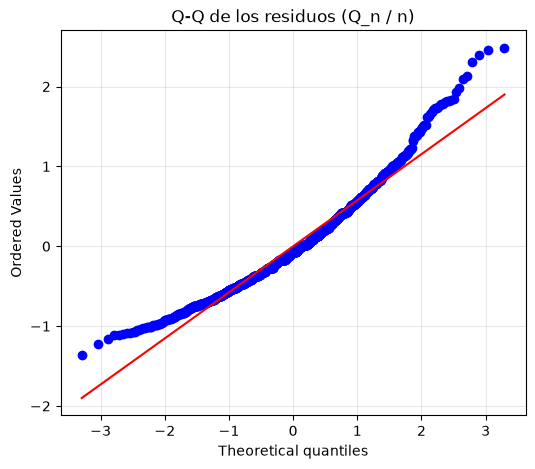

,W,p-valor,¿rechaza al 5 %?
n,,,
10,0.9073,0.0000,True
20,0.9113,0.0000,True
50,0.9425,0.0000,True
100,0.9504,0.0000,True
200,0.9529,0.0000,True
500,0.9657,0.0001,True
1000,0.9626,0.0000,True


In [31]:
# %% 4.2 d) Normalidad de los residuos
res_q_todos = r_q_todos["resid"]
W_q, p_q = stats.shapiro(res_q_todos)
print(f"Shapiro-Wilk, residuos (todos los n): W = {W_q:.4f}, p-valor = {p_q:.2e}")

fig, ax = plt.subplots(figsize=(6, 5))
stats.probplot(res_q_todos, dist="norm", plot=ax)
ax.set_title("Q-Q de los residuos (Q_n / n)")
ax.grid(alpha=0.3)
plt.show()

# Shapiro-Wilk por cada n
b0_hat_q, b1_hat_q = r_q_todos["beta"]
filas_qd = []
for m in ns:
    res_m = (np.array(qn_tamanos[m]) / m) - (b0_hat_q + b1_hat_q * np.log(m))
    W_m, p_m = stats.shapiro(res_m)
    filas_qd.append({"n": m, "W": W_m, "p-valor": p_m, "¿rechaza al 5 %?": p_m < 0.05})

tabla_42d = pd.DataFrame(filas_qd).set_index("n")
display(tabla_42d.round(4))